# 🛍️ Customer Segmentation Using K-Means Clustering

## Project Overview

This project uses unsupervised machine learning to segment customers based on their purchasing behavior.

The goal is to identify groups of customers with similar characteristics and translate these segments into actionable business strategies.

### Techniques Used
- Exploratory Data Analysis (EDA)
- Data Cleaning
- Feature Engineering
- RFM Analysis
- Feature Scaling
- K-Means Clustering
- Cluster Visualization
- Business Interpretation

## 1. Business Understanding

### Problem Statement

An online retailer has transactional data containing information about customer purchases.

However, the retailer does not have predefined customer segments.

The objective of this project is to use customer purchasing behavior to discover meaningful customer groups using unsupervised machine learning.

### Business Objective

The business would like to:

- Identify different types of customers.
- Understand purchasing behavior within each group.
- Identify high-value customers.
- Identify customers who may require targeted marketing.
- Develop strategies tailored to different customer segments.

### Machine Learning Approach

Since there are no predefined customer labels, this project uses **unsupervised learning**.

K-Means clustering will be used to group customers based on similarities in their purchasing behavior.

## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings('ignore')

## 2. Loading the Dataset

In [2]:
df= pd.read_excel('C:/Users/User/Desktop/Data science^MLportfolio/Customer Segmentation/data/Online Retail.xlsx')

## 3. Data Understanding

Before cleaning the dataset, we examine its structure, data types, missing values, and basic statistics to understand the quality and characteristics of the data.

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.shape

(541909, 8)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [6]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [7]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [9]:
df.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

In [10]:
df['CustomerID'].nunique()

4372

In [11]:
df['Country'].nunique()

38

In [12]:
df['Country'].value_counts().head(10)

Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64

In [13]:
df['Quantity'].describe()

count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

In [14]:
df['UnitPrice'].describe()

count    541909.000000
mean          4.611114
std          96.759853
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64

In [15]:
df[df['Quantity'] < 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


country_counts= df['Country'].value_counts().head(10)
plt.figure(figsize= (10,6))
sns.barplot(
    x=country_counts.values,
    y= country_counts.index
)
plt.title('Top 10 Countries by Number of Transactions')
plt.xlabel('Number of Transactions')
plt.ylabel('Country')
plt.show()


## 4. Data Cleaning

### Handling Missing Customer IDs

CustomerID is essential for customer segmentation because it allows us to associate individual transactions with specific customers.

Transactions without a CustomerID cannot be reliably assigned to a customer, so they will be removed from the analysis.

In [16]:
df=df.dropna(subset=['CustomerID'])

In [17]:
df.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [18]:
df.duplicated().sum()

np.int64(5225)

In [19]:
df= df.drop_duplicates()

In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
df[df['Quantity']<0].shape

(8872, 8)

In [22]:
df=df[df['Quantity']>0]

In [23]:
df['Quantity'].describe()

count    392732.000000
mean         13.153718
std         181.588420
min           1.000000
25%           2.000000
50%           6.000000
75%          12.000000
max       80995.000000
Name: Quantity, dtype: float64

In [24]:
df[df['UnitPrice']<=0].shape

(40, 8)

In [25]:
df=df[df['UnitPrice']>0]

In [26]:
df['UnitPrice'].describe()

count    392692.000000
mean          3.125914
std          22.241836
min           0.001000
25%           1.250000
50%           1.950000
75%           3.750000
max        8142.750000
Name: UnitPrice, dtype: float64

In [27]:
df['TotalSpent'] = df['Quantity'] * df['UnitPrice']


In [28]:
df[['Quantity', 'UnitPrice', 'TotalSpent']].head()

,Quantity,UnitPrice,TotalSpent
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


## 5. Customer-level feature engineering

In [29]:

df['InvoiceDate'].min(), df['InvoiceDate'].max()

(Timestamp('2010-12-01 08:26:00'), Timestamp('2011-12-09 12:50:00'))

In [30]:
reference_date= df['InvoiceDate'].max() + pd.Timedelta(days=1)
reference_date

Timestamp('2011-12-10 12:50:00')

In [31]:
rfm= df.groupby('CustomerID').agg({
   'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalSpent': 'sum'
})

In [32]:
rfm.columns= ['Recency', 'Frequency', 'Monetary']

In [33]:
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [34]:
rfm.shape

(4338, 3)

In [35]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


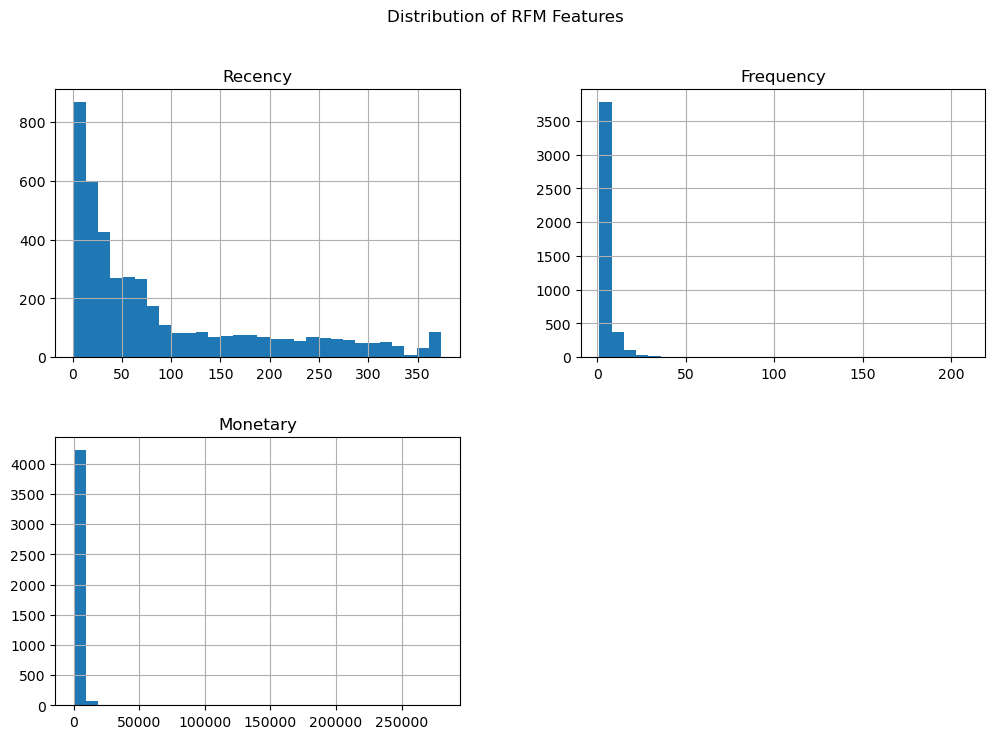

In [36]:
rfm.hist(figsize=(12, 8), bins=30)

plt.suptitle('Distribution of RFM Features')
plt.show()

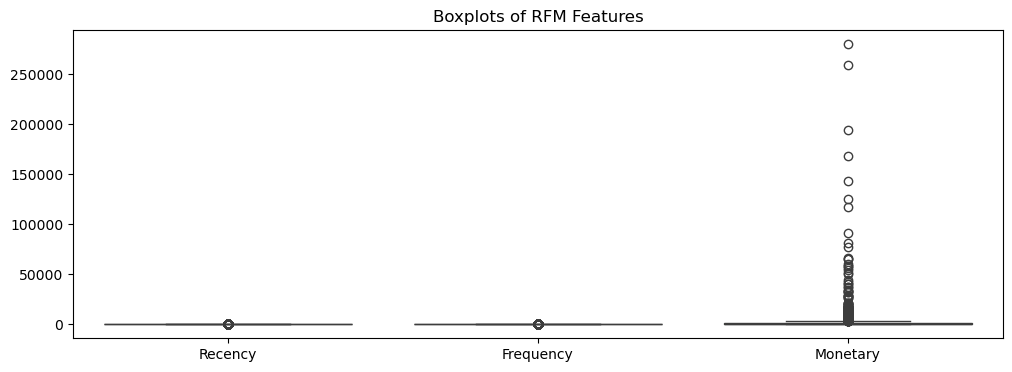

In [37]:
plt.figure(figsize=(12, 4))

sns.boxplot(data=rfm)

plt.title('Boxplots of RFM Features')
plt.show()

## 6. Preparing Features for Clustering

The RFM features will be used as inputs to the K-Means clustering algorithm.

Because the three features have different numerical scales, they will be standardized before clustering.

In [38]:
features= rfm[['Recency', 'Frequency', 'Monetary']]
features.head(10)

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40
12352.0,36,8,2506.04
12353.0,204,1,89.00
12354.0,232,1,1079.40
12355.0,214,1,459.40


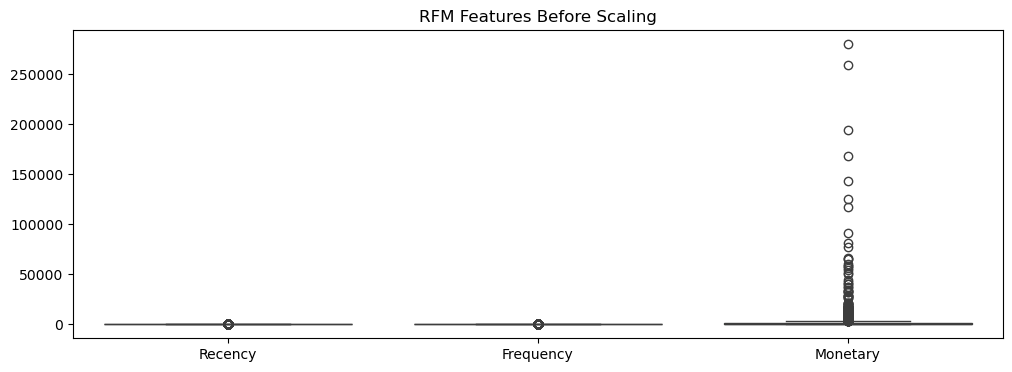

In [39]:
plt.figure(figsize=(12, 4))

sns.boxplot(data=features)

plt.title('RFM Features Before Scaling')
plt.show()

In [40]:
features.skew()

Recency       1.246048
Frequency    12.067031
Monetary     19.339368
dtype: float64

In [41]:

rfm_log = np.log1p(features)

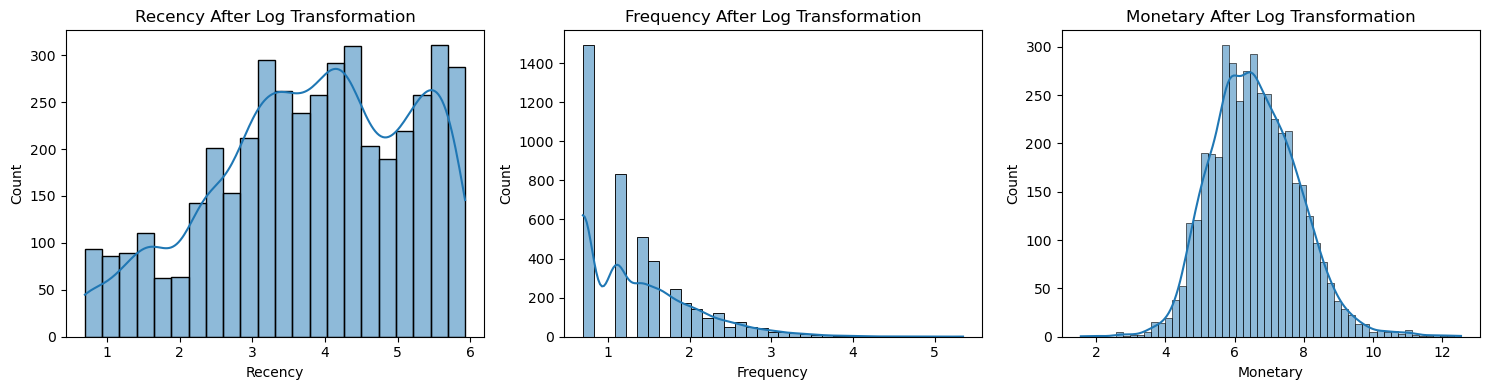

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, column in enumerate(rfm_log.columns):
    sns.histplot(rfm_log[column], kde=True, ax=axes[i])
    axes[i].set_title(f'{column} After Log Transformation')

plt.tight_layout()
plt.show()

In [43]:
scaler= StandardScaler()

In [44]:
rfm_scaled= scaler.fit_transform(rfm_log)

In [45]:
rfm_scaled= pd.DataFrame(
    rfm_scaled,
    columns= rfm_log.columns,
    index= rfm.index
)

In [46]:
rfm_scaled.head(10)

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,1.461993,-0.955214,3.707716
12347.0,-2.038734,1.074425,1.414903
12348.0,0.373104,0.386304,0.720024
12349.0,-0.623086,-0.955214,0.702287
12350.0,1.424558,-0.955214,-0.614514
12352.0,-0.164029,1.246868,0.984108
12353.0,1.113550,-0.955214,-1.659989
12354.0,1.209086,-0.955214,0.315129
12355.0,1.149091,-0.955214,-0.362767


In [47]:
rfm_scaled.mean()

Recency     -8.025955e-17
Frequency   -8.189750e-18
Monetary    -3.669008e-16
dtype: float64

In [48]:
rfm_scaled.std()

Recency      1.000115
Frequency    1.000115
Monetary     1.000115
dtype: float64

In [49]:
inertia= []
K_range= range(2,11)
for k in K_range:
    kmeans= KMeans(
        n_clusters= k,
        random_state= 42,
        n_init= 10
    )
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

In [50]:
for k, value in zip (K_range, inertia):
    print (f"k={k}: Inertia= {value:.2f}")

k=2: Inertia= 6483.59
k=3: Inertia= 4869.49
k=4: Inertia= 3939.05
k=5: Inertia= 3296.71
k=6: Inertia= 2855.76
k=7: Inertia= 2548.82
k=8: Inertia= 2336.34
k=9: Inertia= 2156.01
k=10: Inertia= 2005.75


plt.figure(figsize=(10, 6))

plt.plot(
    K_range,
    inertia,
    marker='o'
)

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')

plt.xticks(K_range)

plt.show()

In [51]:
from sklearn.metrics import silhouette_score

In [52]:
silhouette_scores = []

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(rfm_scaled)
    
    score = silhouette_score(rfm_scaled, labels)
    
    silhouette_scores.append(score)

In [53]:
for k, score in zip(K_range, silhouette_scores):
    print(f"K = {k}: Silhouette Score = {score:.3f}")

K = 2: Silhouette Score = 0.433
K = 3: Silhouette Score = 0.337
K = 4: Silhouette Score = 0.338
K = 5: Silhouette Score = 0.316
K = 6: Silhouette Score = 0.312
K = 7: Silhouette Score = 0.309
K = 8: Silhouette Score = 0.303
K = 9: Silhouette Score = 0.281
K = 10: Silhouette Score = 0.277


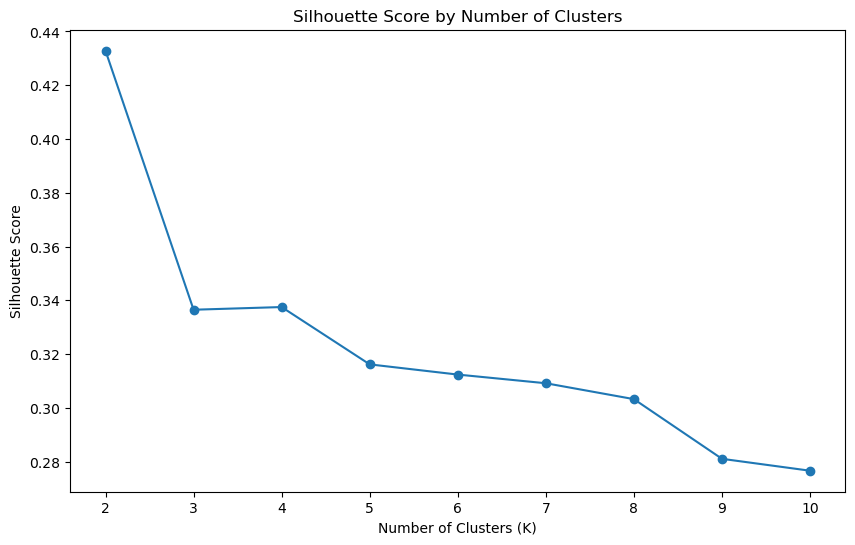

In [54]:
plt.figure(figsize=(10, 6))

plt.plot(
    K_range,
    silhouette_scores,
    marker='o'
)

plt.title('Silhouette Score by Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')

plt.xticks(K_range)

plt.show()

## K-Means Clustering

Based on the clustering evaluation, K = 2 provides the highest silhouette score among the tested values.

Therefore, a K-Means model with two clusters will be used as the initial segmentation model.

In [55]:
kmeans= KMeans(
    n_clusters= 2,
    random_state= 42,
    n_init = 10
)

In [56]:
cluster_labels= kmeans.fit_predict(rfm_scaled)

In [57]:
np.unique(cluster_labels, return_counts= True)

(array([0, 1], dtype=int32), array([2672, 1666]))

In [58]:
rfm['cluster']=cluster_labels

In [59]:
rfm.head(10)

,Recency,Frequency,Monetary,cluster
CustomerID,,,,
12346.0,326,1,77183.60,1
12347.0,2,7,4310.00,1
12348.0,75,4,1797.24,1
12349.0,19,1,1757.55,0
12350.0,310,1,334.40,0
12352.0,36,8,2506.04,1
12353.0,204,1,89.00,0
12354.0,232,1,1079.40,0
12355.0,214,1,459.40,0


In [60]:
cluster_summary= rfm.groupby('cluster')[[
    'Recency',
    'Frequency',
    'Monetary'
]].mean()
cluster_summary

,Recency,Frequency,Monetary
cluster,,,
0,134.091317,1.671033,495.594945
1,25.888956,8.443577,4539.603362


In [61]:
cluster_sizes= rfm['cluster'].value_counts().sort_index()
cluster_sizes

cluster
0    2672
1    1666
Name: count, dtype: int64

In [62]:
cluster_percentages = (
    rfm['cluster']
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

cluster_percentages

cluster
0    61.595205
1    38.404795
Name: proportion, dtype: float64

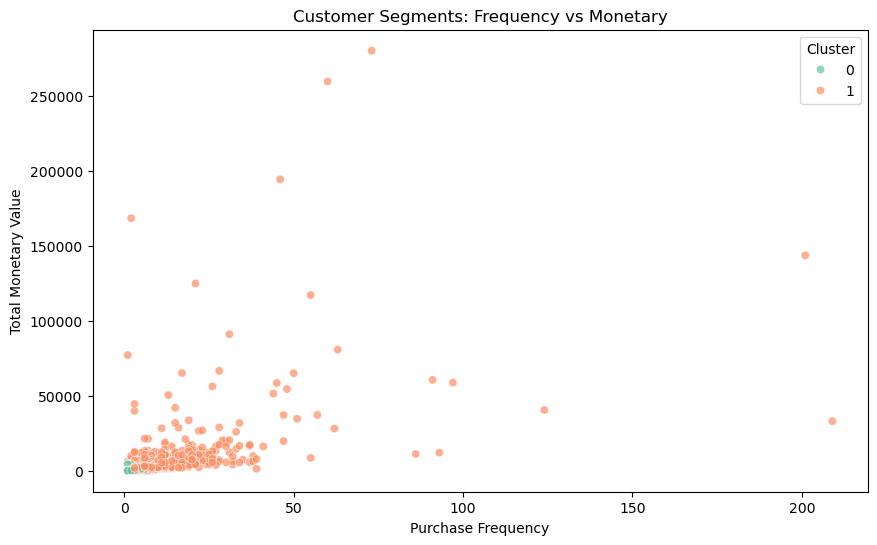

In [63]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='cluster',
    palette='Set2',
    alpha=0.7
)

plt.title('Customer Segments: Frequency vs Monetary')
plt.xlabel('Purchase Frequency')
plt.ylabel('Total Monetary Value')
plt.legend(title='Cluster')

plt.show()

In [64]:
cluster_summary = rfm.groupby('cluster').agg(
    Customers=('cluster', 'size'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
).round(2)

cluster_summary

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
cluster,,,,
0,2672,134.09,1.67,495.59
1,1666,25.89,8.44,4539.60


In [65]:
cluster_summary['Customer_Percentage'] = (
    cluster_summary['Customers']
    / cluster_summary['Customers'].sum()
    * 100
).round(2)

cluster_summary

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Percentage
cluster,,,,,
0,2672,134.09,1.67,495.59,61.6
1,1666,25.89,8.44,4539.60,38.4


In [66]:
cluster_names = {
    0: 'Low-Engagement Customers',
    1: 'High-Value Customers'
}

rfm['Segment'] = rfm['cluster'].map(cluster_names)

##  Customer Segment Distribution

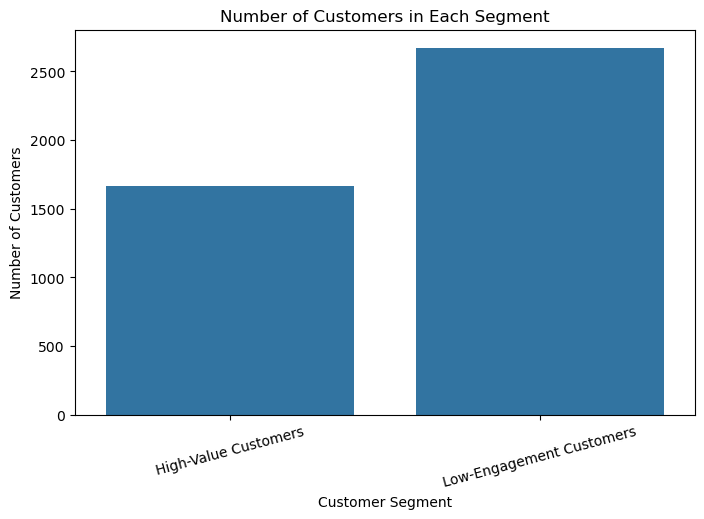

In [67]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x='Segment'
)

plt.title('Number of Customers in Each Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')

plt.xticks(rotation=15)

plt.show()

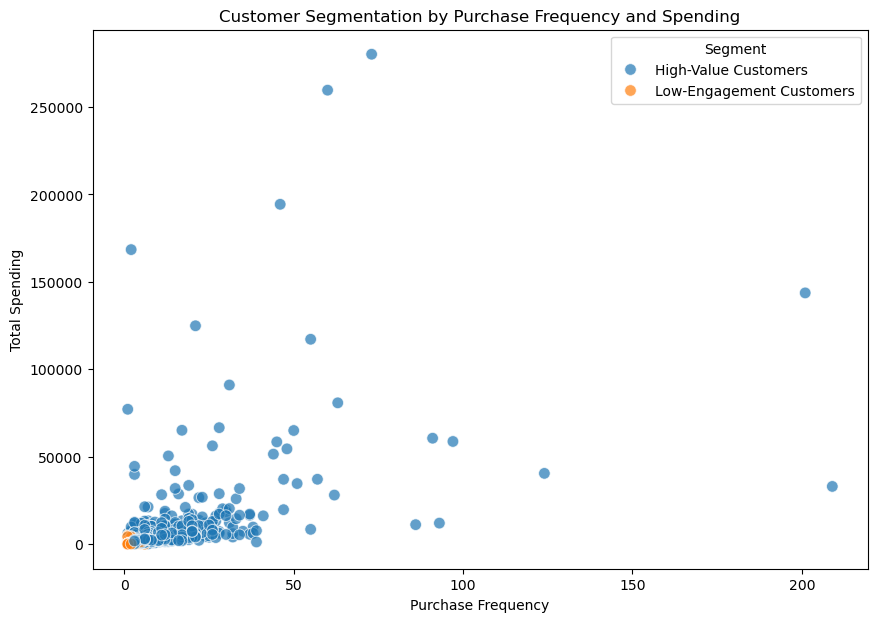

In [68]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Segment',
    s=70,
    alpha=0.7
)

plt.title('Customer Segmentation by Purchase Frequency and Spending')
plt.xlabel('Purchase Frequency')
plt.ylabel('Total Spending')

plt.show()